# Compare all methods across datasets

This offline tutorial compares thirteen methods on two small datasets and prints repeated-run summaries. Every method uses the same input contract. The tiny networks and training budgets demonstrate the workflow—not paper-level accuracy. Run all cells in order using the environment where pymv is installed.

In [1]:
import numpy as np
import pandas as pd
from pymv.data import MultiViewDataset, simulate_missing_views
from pymv.experiment import Experiment, GridSearchExperiment, RandomSearchExperiment, OptunaSearchExperiment
from pymv.metrics import clustering_accuracy, nmi_score, silhouette_score
from pymv.models import (LMGEC, SCM, IDEC, COMPLETER, DCP, MFLVC, CONAN, DGF,
                         SGLA, UMC, GCoMVKM, MultiViewKMeans, MultiViewSpectralClustering)

def dataset(name, noise, seed):
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(3), 16)
    views = [rng.normal(size=(3, dim))[labels] * 3 +
             rng.normal(scale=noise, size=(48, dim)) for dim in (6, 8)]
    return MultiViewDataset(views, labels=labels, name=name)

clean = dataset("clean", .3, 1)
noisy = dataset("noisy", 1.5, 2)

## Run a comparison

`Experiment` evaluates every dataset/model pair. Labels are used only by the metrics. Each model uses K=3 because both datasets have three classes; for datasets with different K, prepare separate jobs. Repeats receive distinct seeds.

In [2]:
small = dict(n_clusters=3, embedding_dim=4, hidden_dims=(16,), max_iter=2,
             batch_size=16, n_init=2, device="cpu")
models = [
    MultiViewKMeans(3, n_init=2, max_iter=10),
    MultiViewSpectralClustering(3, n_init=2, max_iter=2, n_neighbors=5),
    LMGEC(3, embedding_dim=4, max_iter=3),
    SCM(3, hidden_dims=(16,), embedding_dim=4, projection_dim=4, max_iter=2, batch_size=16),
    IDEC(**small, pretrain_epochs=1, update_interval=1),
    COMPLETER(**small, prediction_dims=(8, 4), prediction_start=0),
    DCP(**small, prediction_dims=(8, 4), prediction_start=0),
    MFLVC(**small, projection_dim=4, pretrain_epochs=1, finetune_epochs=1),
    CONAN(3, hidden_dims=(16,), embedding_dim=4, projection_dim=4, max_iter=2, batch_size=16),
    DGF(3, embedding_dim=4, num_layers=2, max_iter=2, batch_size=16,
        walks_per_node=1, n_init=2),
    SGLA(3, n_neighbors=5, max_iter=5, n_init=2),
    GCoMVKM(3, max_iter=5),
    UMC(**small, pretrain_epochs=1),
]
results = Experiment(
    datasets=[clean, noisy], models=models,
    metrics={"ACC": clustering_accuracy, "NMI": nmi_score},
    runs=2, seed=42, save_path="experiments/offline-comparison",
).run()

/home/abdelhak/Codes/library/graphs/src/pymv/models/_graphs.py:46: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(np.stack([coo.row, coo.col]), coo.data,


## A compact table and portable export

The runner already prints configuration and score tables. Build a compact DataFrame from the same report, or export the full JSON/CSV ZIP including every run.

In [3]:
rows = []
for entry in results.report["experiments"]:
    metrics = entry["aggregate"]["metrics"]
    rows.append({"dataset": entry["dataset"]["name"], "model": entry["model"]["name"],
                 **{name: f"{value['mean']:.3f} ± {value['std']:.3f}"
                    for name, value in metrics.items()},
                 "failed_runs": entry["aggregate"]["failed_runs"]})
summary = pd.DataFrame(rows)
display(summary)
assert summary.failed_runs.sum() == 0
results.export("experiments/offline-comparison/all-methods.zip")

,dataset,model,ACC,NMI,failed_runs
0,clean,MultiViewKMeans,1.000 ± 0.000,1.000 ± 0.000,0
1,clean,MultiViewSpectralClustering,1.000 ± 0.000,1.000 ± 0.000,0
2,clean,LMGEC,0.667 ± 0.000,0.734 ± 0.000,0
3,clean,SCM,1.000 ± 0.000,1.000 ± 0.000,0
4,clean,IDEC,1.000 ± 0.000,1.000 ± 0.000,0
5,clean,COMPLETER,1.000 ± 0.000,1.000 ± 0.000,0
6,clean,DCP,1.000 ± 0.000,1.000 ± 0.000,0
7,clean,MFLVC,0.333 ± 0.000,0.000 ± 0.000,0
8,clean,CONAN,0.333 ± 0.000,0.000 ± 0.000,0
9,clean,DGF,1.000 ± 0.000,1.000 ± 0.000,0


PosixPath('experiments/offline-comparison/all-methods.zip')

## Supply several graph relations per view

Graph construction below uses features, never labels. The dataset fuses the two relations for each view before passing them to a graph-aware model. DGF without supplied graphs constructs its own feature graphs; this example exercises explicit graph inputs.

In [4]:
from sklearn.neighbors import kneighbors_graph

relations = []
for x in clean.Xs:
    graphs = []
    for neighbors in (3, 6):
        a = kneighbors_graph(x, neighbors, include_self=False)
        graphs.append(a.maximum(a.T))
    relations.append(graphs)
graph_data = MultiViewDataset(clean.Xs, As=relations, labels=clean.labels, name="multi-relation")
graph_results = Experiment(
    graph_data, [LMGEC(3, embedding_dim=4, max_iter=3),
                 DGF(3, embedding_dim=4, num_layers=2, max_iter=2, batch_size=16, walks_per_node=1)],
    {"NMI": nmi_score}, runs=2, seed=42, save_path="experiments/graphs",
).run()

## Missing views and single-view inputs

COMPLETER and DCP consume observation masks and need at least two fully observed training samples. Other models require explicit imputation. The same dataset contract also supports a single view.

In [5]:
incomplete = simulate_missing_views(clean, .2, random_state=42)
missing_results = Experiment(
    incomplete, [COMPLETER(**small, prediction_dims=(8, 4), prediction_start=0),
                 DCP(**small, prediction_dims=(8, 4), prediction_start=0)],
    {"NMI": nmi_score}, runs=2, seed=42, save_path="experiments/missing",
).run()
single = MultiViewDataset([clean.Xs[0]], labels=clean.labels, name="one-view")
single.fit(MultiViewKMeans(3, random_state=42)).labels_[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

## Compare loss trajectories carefully

Normalized trajectories show within-run progress, not a common objective across algorithms. A lower normalized loss does not establish a better clustering. Run 1 is used as the representative.

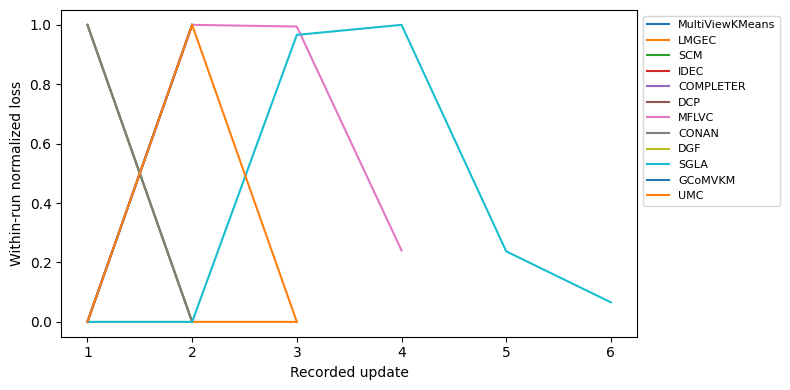

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for entry in results.report["experiments"]:
    if entry["dataset"]["name"] != "clean":
        continue
    trajectory = entry["runs"][0].get("normalized_loss_history")
    if trajectory:
        ax.plot(np.arange(1, len(trajectory)+1), trajectory, label=entry["model"]["name"])
ax.set(xlabel="Recorded update", ylabel="Within-run normalized loss")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout()
plt.show()